In [1]:
# Code written by Claude (Anthropic, Claude Opus 5.5) for Google Colab compatibility.
# Adapted from the install cell of demo_2/notebooks/fr/07_llm_and_rag_FP16.ipynb (IFT 6758).
# OPTIONAL: once per new Colab runtime (version 2025.07 = Python 3.11, T4 GPU).
INSTALL_COLAB = False  # Set to True to install, then back to False

import sys
import subprocess
from pathlib import Path
from importlib.metadata import version

REPO_URL = "https://github.com/Mahdi267/NHL-data-analysis.git"
REPO_DIR = Path("/content/NHL-data-analysis")
REQ_FILE = Path("/content/requirements_colab.txt")

# Detect Colab; otherwise the local .venv is used
try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    print("Local environment: install skipped (uv sync --extra llm in the terminal).")
elif not INSTALL_COLAB:
    print("Install skipped. Set INSTALL_COLAB = True on a new Colab runtime.")
else:
    if sys.version_info[:2] != (3, 11):
        raise RuntimeError("Python 3.11 required: Runtime → Change runtime type → version 2025.07.")

    # 1. Project code (public repository: no credentials)
    if not REPO_DIR.exists():
        subprocess.check_call(["git", "clone", REPO_URL, str(REPO_DIR)])
    else:
        subprocess.check_call(["git", "-C", str(REPO_DIR), "pull"])

    # 2. Same versions as local (uv.lock), except torch: we keep Colab's,
    #    built for its CUDA driver (the torch in the lock is a CUDA 13 build)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "uv>=0.8,<1"])
    export = subprocess.check_output(
        [sys.executable, "-m", "uv", "export", "--frozen", "--extra", "llm",
         "--no-dev", "--no-hashes", "--no-emit-project"],
        cwd=REPO_DIR, text=True,
    )
    skip = ("torch==", "triton==", "nvidia-")
    lines = [line for line in export.splitlines() if not line.startswith(skip)]
    lines.append(f"torch=={version('torch').split('+')[0]}")  # Pin the torch already installed
    REQ_FILE.write_text("\n".join(lines))

    # 3. Install into the notebook's Python, then the project in editable mode
    uv_install = [sys.executable, "-m", "uv", "pip", "install", "--python", sys.executable]
    subprocess.check_call(uv_install + ["-r", str(REQ_FILE)])
    subprocess.check_call(uv_install + ["--no-deps", "-e", str(REPO_DIR)])
    print("Install done. Runtime → Restart session, then set INSTALL_COLAB = False.")

Local environment: install skipped (uv sync --extra llm in the terminal).


In [2]:
# Code written by Claude (Anthropic, Claude Opus 5.5) for Google Colab compatibility.
import os
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Adjust to THIS notebook's folder (notebooks/ or visualizations/): relative paths depend on it
NOTEBOOK_DIR = Path("/content/NHL-data-analysis/ift6758/notebooks")
if IN_COLAB:
    os.chdir(NOTEBOOK_DIR)
print("Working directory:", Path.cwd())

from ift6758.llm.qwen_utils import check_env

check_env()  # Should show Python 3.11 and CUDA GPU: Tesla T4

Working directory: /Users/jcforget/Maitrise/Cours/IFT 6758/Projet/Github/NHL-data-analysis/ift6758/notebooks
Python: 3.11.15
NumPy: 1.26.4 | pandas: 2.3.3
Transformers: 5.17.0
Sentence Transformers: 6.1.0
CUDA GPU: Unavailable — CPU/Apple GPU fallback


In [3]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from pathlib import Path
from IPython.display import Image, display
import pandasai as pai
from pandasai.llm.base import LLM
from ift6758.llm.qwen_utils import load_qwen, build_messages, generate, check_env
from ift6758.features.simple_visualizations import games_list
import time

check_env()  # Demo 2, for reproductibility

Python: 3.11.15
NumPy: 1.26.4 | pandas: 2.3.3
Transformers: 5.17.0
Sentence Transformers: 6.1.0
CUDA GPU: Unavailable — CPU/Apple GPU fallback


In [4]:
# Workaround written by Claude (Anthropic, Claude Opus 5.5)
# Workaround for a PandasAI 3.0.0 bug: charts are saved in <cwd>/exports/charts but the folder is not created
Path("exports/charts").mkdir(parents=True, exist_ok=True)

# Seasons used by the 8 evaluation questions (start year)
SEASONS = [2016, 2017, 2019, 2021, 2022, 2023]
data = pd.concat([games_list(s) for s in SEASONS], ignore_index=True)
print(data.shape)
print(data.groupby(["season", "game_type"])["game_id"].nunique())  # Check that the seasons are complete

(504006, 25)
season    game_type     
20162017  playoffs            87
          regular season    1230
20172018  playoffs            84
          regular season    1271
20192020  playoffs            86
          regular season    1082
20212022  playoffs            89
          regular season    1312
20222023  playoffs            88
          regular season    1312
20232024  playoffs            88
          regular season    1312
Name: game_id, dtype: int64


In [5]:
# Sources : ift6758/features/tidy.py (Mahdi), ift6758/features/Q1_P3.txt, NHLyear.download_all (William),
# profil de la saison 2021-22 (89 585 lignes) et types DuckDB vérifiés le 2026-10-17.
dic_des = {
    "game_id": "Integer game identifier, 10 digits: 4-digit season start year + 2-digit game type (02 = regular season, 03 = playoffs) + 4-digit game number. Regular season: game number 0001 to 1312, e.g. game 50 of the 2021-22 regular season is 2021020050. Playoffs: the last 4 digits are 0 + round + matchup + game, e.g. 2018030212 = round 2, matchup 1, game 2.,; game 212 of the 2018-19 playoffs is 2018030212.",
    "event_id": "Integer identifier of the event inside its game. Unique only within one game_id.",
    "season": "Integer season identifier: start year followed by end year, e.g. 20212022 for the 2021-22 season.",
    "situation_code": "4-character text code of the players on ice: away goalie (1 in net, 0 pulled), away skaters, home skaters, home goalie. Example: '1451' = away 4 skaters vs home 5 skaters, both goalies in net.",
    "period": "Integer period number: 1 to 3 are regulation, 4 is overtime. In the regular season, period 5 is the shootout; in the playoffs, periods 5 and more are extra overtimes.",
    "time": "Text 'MM:SS', time elapsed in the period when the event happened.",
    "shooter_id": "Player id of the player who took the shot. For goals it is the scorer, so shooter_id covers every row and is the column to use for a player's shots and goal percentage.",
    "scorer_id": "Player id of the goal scorer. Only filled when event_type is 'goal', empty for shots.",
    "event_type": "Type of event: 'goal' (a scored goal) or 'shot-on-goal' (a shot stopped by the goalie, NOT a goal).",
    "x_coord": "X coordinate of the shot in feet, from -99 to 99. Center ice is 0; the nets are near x = -89 and x = 89.",
    "y_coord": "Y coordinate of the shot in feet, from -42 to 42. 0 is the middle of the ice.",
    "goalie_id": "Player id of the goalie in net who faced the shot. Empty when the net was empty.",
    "shot_type": "Type of shot: 'wrist', 'snap', 'slap', 'backhand', 'tip-in', 'deflected', 'wrap-around'.",
    "team_id": "Integer id of the team that took the shot. Team ids: 1 NJD New Jersey, 2 NYI NY Islanders, 3 NYR NY Rangers, 4 PHI Philadelphia, 5 PIT Pittsburgh, 6 BOS Boston, 7 BUF Buffalo, 8 MTL Montreal, 9 OTT Ottawa, 10 TOR Toronto, 12 CAR Carolina, 13 FLA Florida, 14 TBL Tampa Bay, 15 WSH Washington, 16 CHI Chicago, 17 DET Detroit, 18 NSH Nashville, 19 STL St. Louis, 20 CGY Calgary, 21 COL Colorado, 22 EDM Edmonton, 23 VAN Vancouver, 24 ANA Anaheim, 25 DAL Dallas, 26 LAK Los Angeles, 28 SJS San Jose, 29 CBJ Columbus, 30 MIN Minnesota, 52 WPG Winnipeg, 53 ARI Arizona, 54 VGK Vegas, 55 SEA Seattle.",
    "homeTeam_id": "Integer id of the home team of the game. A row is a home team shot when team_id = homeTeam_id.",
    "homeTeamDefendingSide": "Side of the rink defended by the home team during this period: 'left' or 'right'.",
    "game_type": "Type of game: 'regular season' or 'playoffs' (a game of a playoff series).",
    "shooter": "First name only of the shooter. The last name is in shooter_last_name.",
    "shooter_last_name": "Last name of the shooter.",
    "scorer": "First name only of the goal scorer, empty for shots. The last name is in scorer_last_name.",
    "scorer_last_name": "Last name of the goal scorer, empty for shots.",
    "goalie": "First name only of the goalie in net, empty when the net was empty. The last name is in goalie_last_name.",
    "goalie_last_name": "Last name of the goalie in net, empty when the net was empty.",
    "emptyNet": "Boolean: True when no goalie was in net (goalie pulled), False otherwise.",
    "strength": "Strength of the shooting team, ONLY for goals: 'even', 'power play' or 'shorthanded'. Empty for every shot, SO IT CANNOT be used to count shots or to compute a goal percentage by strength.",
    "away_players": "Integer number of away players on ice (goalie + skaters), from situation_code. A value of 1 means a shootout attempt or a penalty shot.",
    "home_players": "Integer number of home players on ice (goalie + skaters), from situation_code. A value of 1 means a shootout attempt or a penalty shot.",
}


In [6]:
# Instructions from milestone
table_description = (
    "NHL play-by-play data: one row per shot on goal or goal (missed shots, blocked shots, passes, assists, "
    "penalties and hits are not recorded). Goal percentage = number of 'goal' rows / total number of rows "
    "(goals + shots on goal) for the selected group. Teams are identified only by team_id (see its description). "
    "If a question needs information that is not in this table, answer with type 'string' and the value: "
    "'I cannot answer this question with the available data.'"
)

In [7]:
# Adaptation of pandasai/llm/fake.py
class QwenLLM(LLM):
    def __init__(self, model, tokenizer, max_new_tokens=1024):
        # Initialise for every new question
        self.model = model
        self.tokenizer = tokenizer
        self.max_new_tokens = max_new_tokens
        self.n_calls = 0  # Reset before each question
        self.last_prompt = None

    def call(self, instruction, context=None) -> str:
        self.n_calls += 1
        self.last_prompt = instruction.to_string()
        answer = generate(
            model=self.model,
            tokenizer=self.tokenizer,
            messages=build_messages(self.last_prompt, context=None, system=None),
            max_new_tokens=self.max_new_tokens,
            do_sample=False,
        )
        return answer["answer"]

    @property
    def type(self) -> str:
        return "qwen_local"

In [8]:
model, tokenizer, device = load_qwen()
qwen = QwenLLM(model, tokenizer)
# max_retries: number of new attempts PandasAI makes after an error (default 3)
pai.config.set({"llm": qwen, "max_retries": 3})

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [9]:
def make_pai_df(data):
    """Creates a new pandasai dataframe with columns description

    New object for each question : no data from previous questions.
    """
    df_q = pai.DataFrame(data)
    for col in df_q.schema.columns:
        if col.name in dic_des:
            col.description = dic_des[col.name]
    df_q.schema.description = table_description
    return df_q

In [10]:
def ask(question):
    """Ask one question to PandasAI + Qwen and keep what the evaluation table needs.

    :param question: Question in natural language
    :type question: str
    :return: answer, generated code, number of LLM calls and whether it ran
    :rtype: dict
    """
    df_q = make_pai_df(data)  # New object: no memory of the previous questions
    qwen.n_calls = 0
    start = time.time()
    try:
        response = df_q.chat(question)
        ran = type(response).__name__ != "ErrorResponse"
        value = response.value
    except Exception as e:  # PandasAI gave up after max_retries
        response, ran, value = None, False, f"{type(e).__name__}: {e}"
    return {
        "question": question,
        "answer": value,
        "response_type": type(response).__name__,
        "code": df_q._agent.last_generated_code if df_q._agent else None,
        "first_attempt_ran": ran and qwen.n_calls == 1,
        "retries": qwen.n_calls - 1,
        "duration_s": round(time.time() - start, 1),
    }

In [11]:
# Written by Tiffany on 2026-10-15, before any prompt work (ift6758/visualizations/pandasai.ipynb). Do not edit.
EVAL_QUESTIONS = [
    'What is the goal percentage done by shots of type "backhand" in the 2021-2022 season?',
    "Produce a figure that shows the number of shot taken on a empty net for each shot type for season 2021-2022.",
    "Produce a figure that shows the number of goals done for each type of strength for season 2016-2017.",
    "What is the shooting player's id for event 54 in game 411 in the playoffs for season 2019-2020?",
    "What is the score results for game 139 in the regular season 2023-2024?",
    "What is the goal percentage done by player 8480748 in the 2022-2023 season?",
    "What is the most used type of pass for the 2017-2018 season?",
    "What is the player id of my favorite player?",
]

In [12]:
# Adapted from Tiffany's reference code (ift6758/visualizations/pandasai.ipynb), recomputed with the current json2tidy
s21 = data[data["season"] == "20212022"]
s16 = data[data["season"] == "20162017"]
s22 = data[data["season"] == "20222023"]
is_goal = lambda d: d["event_type"] == "goal"

game139 = data[data["game_id"] == 2023020139]
player = s22[s22["shooter_id"] == 8480748]  # shooter_id also covers goals

REFERENCE = {
    1: f"{100 * is_goal(s21[s21['shot_type'] == 'backhand']).mean():.2f} %",
    2: s21.groupby("shot_type")["emptyNet"].sum().to_dict(),
    3: s16[is_goal(s16)].groupby("strength").size().to_dict(),
    4: "Cannot answer: event 54 is a blocked shot, not in the dataset",
    5: game139[is_goal(game139)].groupby("team_id").size().to_dict(),  # LAK (26) 4, TOR (10) 1
    6: f"{100 * is_goal(player).mean():.2f} %",
    7: "Cannot answer: passes are not recorded",
    8: "Cannot answer: favorite player unknown",
}
REFERENCE

{1: 'nan %',
 2: {},
 3: {},
 4: 'Cannot answer: event 54 is a blocked shot, not in the dataset',
 5: {10.0: 1, 26.0: 4},
 6: 'nan %',
 7: 'Cannot answer: passes are not recorded',
 8: 'Cannot answer: favorite player unknown'}


===== Q1 : What is the goal percentage done by shots of type "backhand" in the 2021-2022 season?
Answer: 12.44929313659668 | retries: 1

===== Q2 : Produce a figure that shows the number of shot taken on a empty net for each shot type for season 2021-2022.
Answer: No shots on empty net were recorded for the 2021-2022 season. | retries: 0

===== Q3 : Produce a figure that shows the number of goals done for each type of strength for season 2016-2017.
Answer: exports/charts/temp_chart_26de8075-361e-42d9-a214-0b625a46dcb6.png | retries: 0


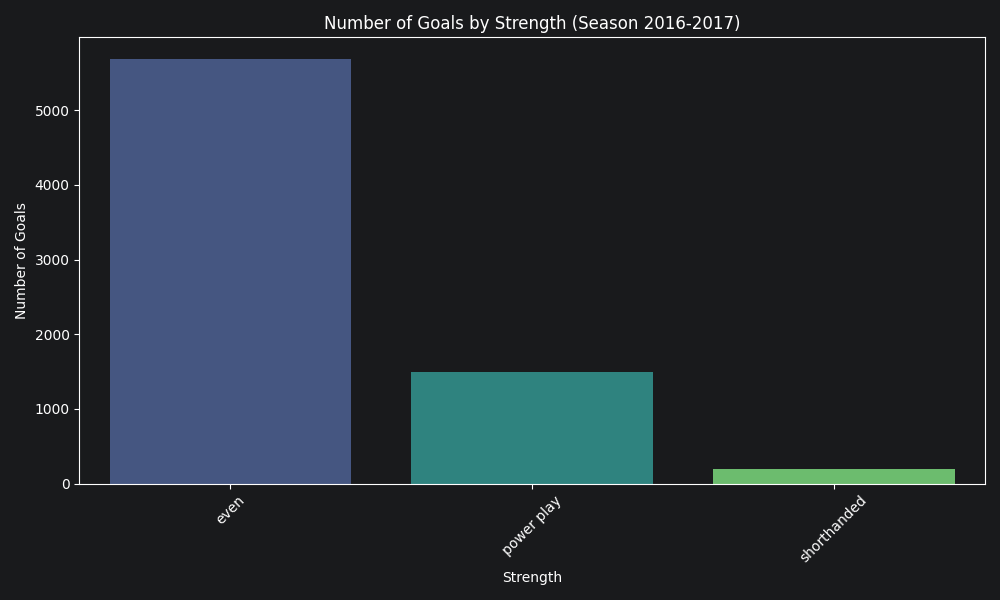


===== Q4 : What is the shooting player's id for event 54 in game 411 in the playoffs for season 2019-2020?
Answer: I cannot answer this question with the available data. | retries: 0

===== Q5 : What is the score results for game 139 in the regular season 2023-2024?
Answer: I cannot answer this question with the available data. | retries: 3

===== Q6 : What is the goal percentage done by player 8480748 in the 2022-2023 season?
Answer: 0.12280701754385964 | retries: 0

===== Q7 : What is the most used type of pass for the 2017-2018 season?
Answer: ExecuteSQLQueryNotUsed: The code must execute SQL queries using the `execute_sql_query` function, which is already defined! | retries: 4

===== Q8 : What is the player id of my favorite player?
Answer: ExecuteSQLQueryNotUsed: The code must execute SQL queries using the `execute_sql_query` function, which is already defined! | retries: 4


In [13]:
results = []
for i, q in enumerate(EVAL_QUESTIONS, start=1):
    print(f"\n===== Q{i} : {q}")
    row = ask(q)
    row["id"] = i
    results.append(row)
    print("Answer:", row["answer"], "| retries:", row["retries"])
    if row["response_type"] == "ChartResponse":
        display(Image(filename=str(row["answer"])))

In [15]:
table = pd.DataFrame(results).set_index("id")[["question", "first_attempt_ran", "retries", "answer", "duration_s"]]
table["reference"] = pd.Series(REFERENCE)
# Filled by hand after comparing each answer (or chart) with the reference
table["final_correct"] = None
table
print(table)

                                             question  first_attempt_ran  \
id                                                                         
1   What is the goal percentage done by shots of t...              False   
2   Produce a figure that shows the number of shot...               True   
3   Produce a figure that shows the number of goal...               True   
4   What is the shooting player's id for event 54 ...               True   
5   What is the score results for game 139 in the ...              False   
6   What is the goal percentage done by player 848...               True   
7   What is the most used type of pass for the 201...              False   
8        What is the player id of my favorite player?              False   

    retries                                             answer  duration_s  \
id                                                                           
1         1                                          12.449293       216.5   
2    